# 02 · Results

Test-set performance of the four models, how it splits by data batch, how training behaves, and
whether the models look at the nodule or at the scanner overlays. Everything is read from
`runs/` (written by `thyroid.train`) and `results/` (written by `thyroid.summarize`). The
Grad-CAM and occlusion cells run the trained models on CPU in a few minutes.

The test set is 157 held-out patients (1473 frames). It was not used for early stopping,
thresholds or model choice.

In [1]:
import json, os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import roc_auc_score, roc_curve

from thyroid.data.dataset import IMAGES, build_transform
from thyroid.explain import gradcam, load_fold, scores
from thyroid.metrics import patient_scores
from thyroid.plotting import CLASS_COLORS, SERIES, TEXT_MUTED, use_style

use_style()
torch.set_num_threads(os.cpu_count())
NAMES = ["vit_b16", "resnet50", "cnn_thesis", "vit_thesis"]
COLORS = dict(zip(NAMES, SERIES))
LABELS = {"vit_b16": "ViT-B/16 (ImageNet)", "resnet50": "ResNet-50 (ImageNet)",
          "cnn_thesis": "thesis CNN (scratch)", "vit_thesis": "thesis ViT (scratch)"}
source = pd.read_csv("data/splits/manifest.csv").set_index("image")["source"]


def fold_predictions(model):
    return {int(p.parent.name[4:]): pd.read_csv(p) for p in sorted(Path(f"runs/{model}").glob("fold*/predictions.csv"))}


def ensemble_test(model):
    """Mean score of the 5 fold models per test image."""
    test = pd.concat([d[d.split == "test"] for d in fold_predictions(model).values()])
    e = test.groupby(["image", "patient_id", "label"], as_index=False).score.mean()
    e["source"] = e.image.map(source)
    return e


def best_fold(model):
    m = {int(p.parent.name[4:]): json.loads(p.read_text()) for p in Path(f"runs/{model}").glob("fold*/metrics.json")}
    return max(m, key=lambda k: m[k]["val"]["image"]["auroc"])


ens = {m: ensemble_test(m) for m in NAMES}

## Summary

In [2]:
summary = pd.read_csv("results/summary.csv")
test = summary[summary["eval"].str.startswith("test")].copy()
test["eval"] = test["eval"].str.replace(r" \(.*fold mean.*\)", " (fold mean ± std)", regex=True)
test.pivot_table(index="model", columns=["level", "eval"], values="auroc", aggfunc="first").loc[NAMES]

level                       image                         \
eval       test (5-fold ensemble) test (fold mean ± std)   
model                                                      
vit_b16                     0.684          0.652 ± 0.026   
resnet50                    0.630          0.612 ± 0.011   
cnn_thesis                  0.550          0.533 ± 0.029   
vit_thesis                  0.449          0.456 ± 0.005   

level                     patient                         
eval       test (5-fold ensemble) test (fold mean ± std)  
model                                                     
vit_b16                     0.752          0.724 ± 0.027  
resnet50                    0.696          0.678 ± 0.018  
cnn_thesis                  0.619          0.578 ± 0.061  
vit_thesis                  0.457          0.461 ± 0.015

AUROC on the test set. *Fold mean* is the average of the 5 fold models, each evaluated on its
own; the *ensemble* averages their scores per frame. Patient level averages a patient's frame
scores. Full metrics (AUPRC, sensitivity, specificity, balanced accuracy) are in
`results/summary.md`.

## ROC curves

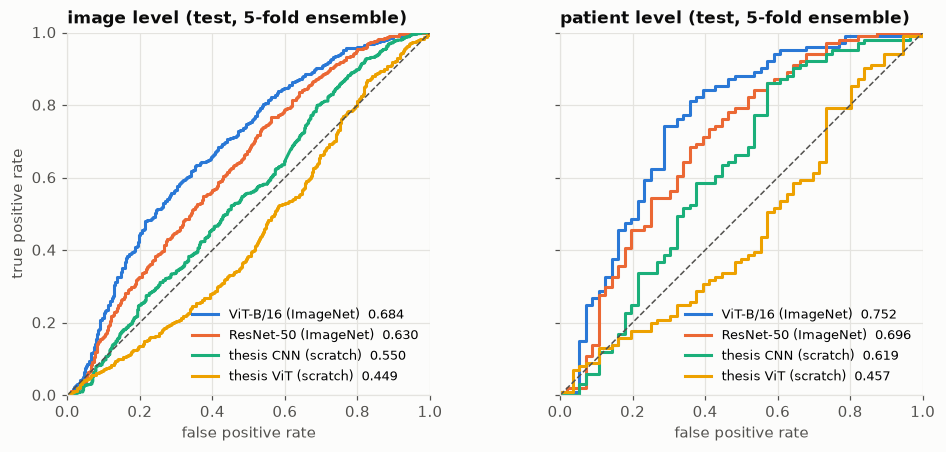

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2), sharey=True)
for ax, level in zip(axes, ["image", "patient"]):
    for m in NAMES:
        e = ens[m]
        if level == "image":
            y, s = e.label.to_numpy(), e.score.to_numpy()
        else:
            _, y, s = patient_scores(e.patient_id.tolist(), e.label.to_numpy(), e.score.to_numpy())
        fpr, tpr, _ = roc_curve(y, s)
        ax.plot(fpr, tpr, color=COLORS[m], lw=2, label=f"{LABELS[m]}  {roc_auc_score(y, s):.3f}")
    ax.plot([0, 1], [0, 1], color=TEXT_MUTED, lw=1, ls="--")
    ax.set(title=f"{level} level (test, 5-fold ensemble)", xlabel="false positive rate", xlim=(0, 1), ylim=(0, 1))
    ax.set_aspect("equal")
    ax.legend(loc="lower right", fontsize=8.5)
axes[0].set_ylabel("true positive rate")
fig.tight_layout()
Path("results/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("results/figures/roc.png", dpi=150, bbox_inches="tight")

The two ImageNet-pretrained models learn a usable signal; ViT-B/16 is the best at both levels.
The thesis architectures trained from scratch stay close to chance: about 6000 training frames
are not enough to train a ViT or a CNN from random weights for this task. The thesis ViT even
ranks test patients slightly *worse* than chance, consistently across its five fold models, so
whatever it fits in training does not transfer.

## Per batch

In [4]:
rows = []
for m in NAMES:
    for src, g in ens[m].groupby("source"):
        _, py, ps = patient_scores(g.patient_id.tolist(), g.label.to_numpy(), g.score.to_numpy())
        rows.append({"model": m, "batch": src, "patients": len(py), "frames": len(g),
                     "auroc image": roc_auc_score(g.label, g.score), "auroc patient": roc_auc_score(py, ps)})
pd.DataFrame(rows).set_index(["model", "batch"]).style.format(precision=3)

ViT-B/16 is weaker on batch 2 (patient AUROC 0.62 vs 0.79), but batch 2 has only 37 test
patients, so its patient-level AUROC is uncertain by roughly ±0.1 and the gap should not be
over-read. The scratch models are below chance on batch 2 at both levels.

## Training curves

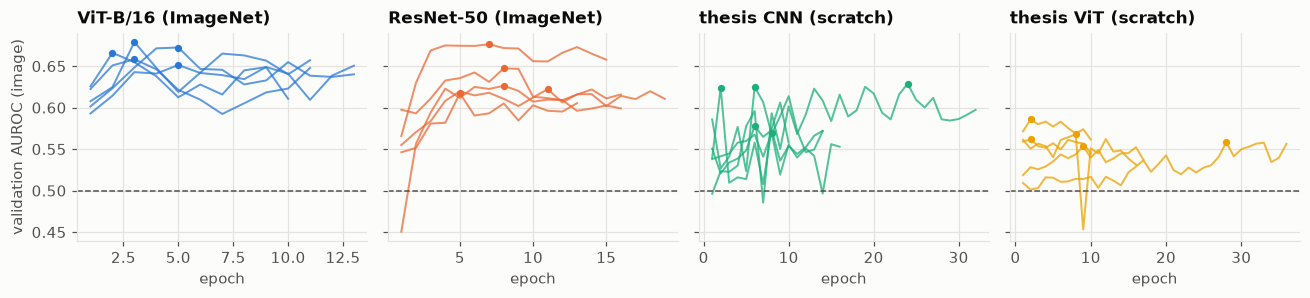

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
for ax, m in zip(axes, NAMES):
    for k in range(5):
        h = pd.read_csv(f"runs/{m}/fold{k}/history.csv")
        ax.plot(h.epoch, h.val_auroc, color=COLORS[m], lw=1.3, alpha=0.75)
        best = h.val_auroc.idxmax()
        ax.scatter(h.epoch[best], h.val_auroc[best], color=COLORS[m], s=14, zorder=3)
    ax.axhline(0.5, color=TEXT_MUTED, lw=1, ls="--")
    ax.set(title=LABELS[m], xlabel="epoch")
axes[0].set_ylabel("validation AUROC (image)")
fig.tight_layout()

One line per fold; the dot marks the epoch that was kept. The pretrained models peak within the
first few epochs and then overfit, and early stopping (patience 8) stops them well before the
epoch budget. Validation AUROC of the scratch models barely leaves 0.5–0.6.

## Where the models look

The frames carry burned-in scanner overlays: header text with the date and exam number, vendor
UI, calipers and colour-Doppler boxes. A model that learned those instead of the tissue would
score well here and fail elsewhere. Two checks, both on the fold model with the best validation
AUROC.

**Grad-CAM.** The four most confident correct patients per class, one frame each, with the
heat map of the predicted class. The top 9% of each frame (date, time, exam number) is masked
in the figure only; the model saw the full frame.

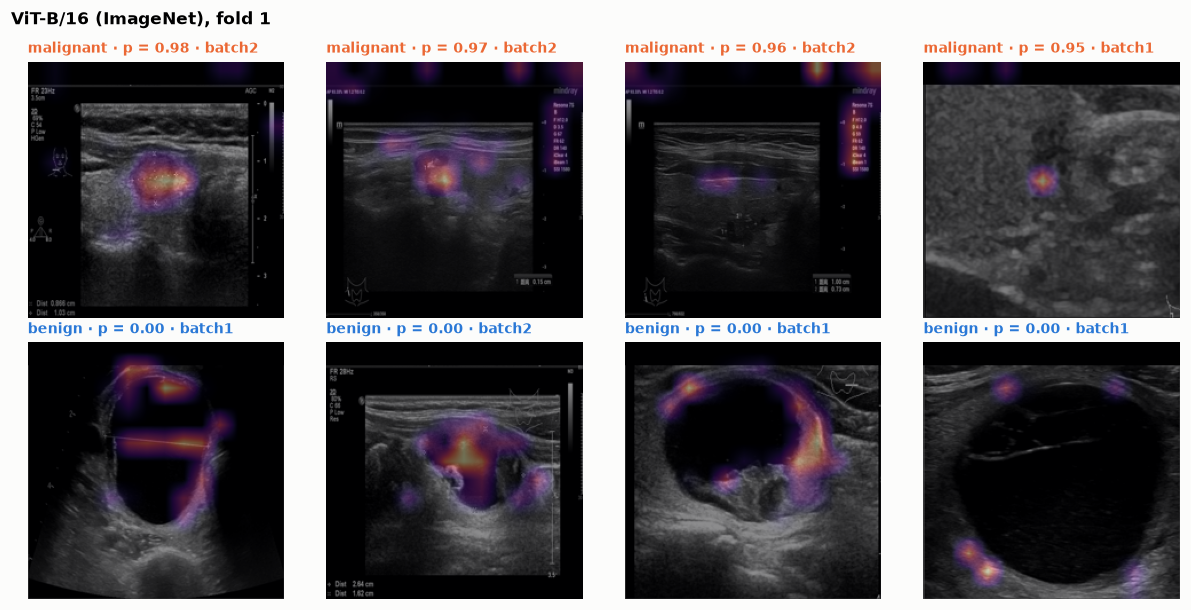

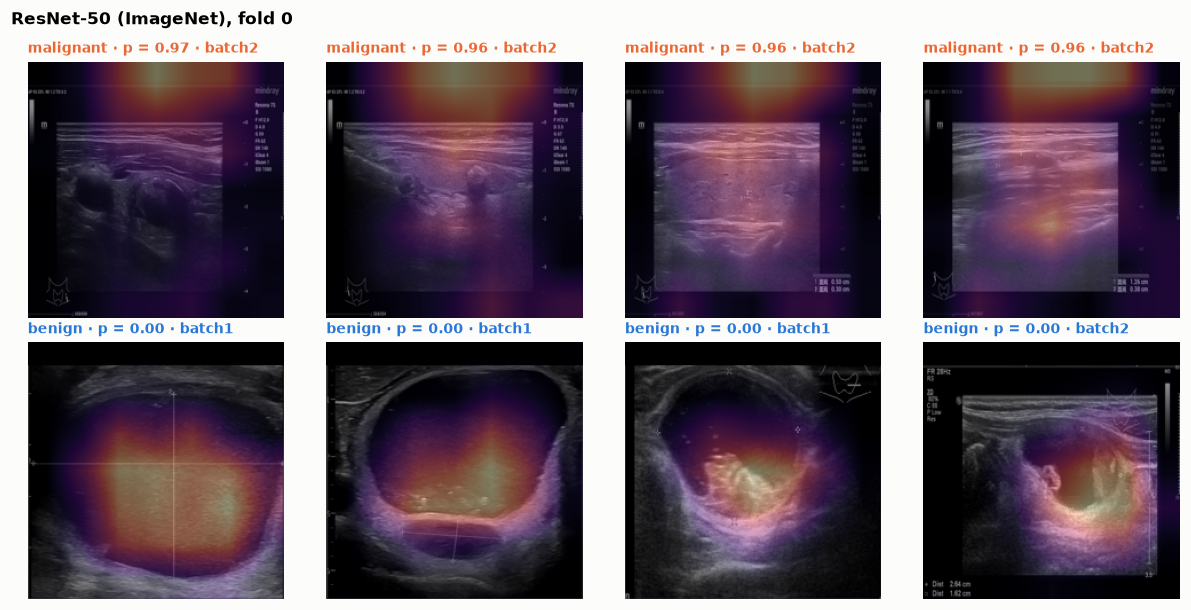

In [6]:
def load_batch(files, edit=None, img_size=224):
    tf = build_transform(img_size, train=False, pretrained=True)
    out = []
    for f in files:
        a = np.asarray(Image.open(IMAGES / f).convert("L")).copy()
        out.append(tf(Image.fromarray(edit(a) if edit else a)))
    return torch.stack(out)


def confident(model, fold, label, n=4):
    p = fold_predictions(model)[fold].query("split == 'test' and label == @label")
    p = p.sort_values("score", ascending=label == 0).drop_duplicates("patient_id")
    return p.head(n)


for m in ["vit_b16", "resnet50"]:
    fold = best_fold(m)
    net = load_fold(m, fold)
    fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
    for row, label in enumerate([1, 0]):
        picks = confident(m, fold, label)
        cams = gradcam(net, load_batch(picks.image), target=label)
        for ax, cam, (_, r) in zip(axes[row], cams, picks.iterrows()):
            img = np.asarray(Image.open(IMAGES / r.image).convert("L").resize((224, 224)), dtype=np.uint8).copy()
            img[: int(224 * 0.09)] = 0
            cls = ["benign", "malignant"][label]
            ax.imshow(img, cmap="gray")
            ax.imshow(cam, cmap="magma", alpha=0.45, vmin=0, vmax=1)
            ax.set_title(f"{cls} · p = {r.score:.2f} · {source[r.image]}", color=CLASS_COLORS[cls], fontsize=9)
            ax.axis("off")
    fig.suptitle(f"{LABELS[m]}, fold {fold}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    if m == "vit_b16":
        fig.savefig("results/figures/gradcam_vit_b16.png", dpi=120, bbox_inches="tight")

Grad-CAM shows single examples and its coarse maps (14 × 14 tokens for the ViT, 7 × 7 for
ResNet-50) can be misleading, so the second check measures the effect of removing image regions
directly.

**Occlusion.** 400 test frames (200 per class) are scored again with parts of the frame set to
black: the header strip, everything outside the central 60% × 60% box, or the central box
itself. If the score came from overlays, masking the header or keeping only the centre would
hurt the most.

In [7]:
def mask_top(a, frac=0.09):
    a[: int(a.shape[0] * frac)] = 0
    return a


def center_box(a):
    h, w = a.shape
    return slice(int(h * 0.2), int(h * 0.8)), slice(int(w * 0.2), int(w * 0.8))


def only_center(a):
    out = np.zeros_like(a)
    box = center_box(a)
    out[box] = a[box]
    return out


def hide_center(a):
    a[center_box(a)] = 0
    return a


EDITS = {"full frame": None, "header masked": mask_top, "centre only": only_center, "centre masked": hide_center}
rows = []
for m in ["vit_b16", "resnet50"]:
    fold = best_fold(m)
    net = load_fold(m, fold)
    p = fold_predictions(m)[fold].query("split == 'test'")
    p = pd.concat([p[p.label == k].sample(200, random_state=0) for k in (0, 1)])
    rows.append({"model": m, **{name: roc_auc_score(p.label, scores(net, load_batch(p.image, edit)))
                                for name, edit in EDITS.items()}})
pd.DataFrame(rows).set_index("model").style.format(precision=3)

,full frame,header masked,centre only,centre masked
model,,,,
vit_b16,0.657,0.650,0.648,0.592
resnet50,0.604,0.594,0.551,0.525


For ViT-B/16, masking the header costs nothing (0.657 → 0.650), and the central box alone keeps
almost all of the performance (0.648). Hiding the centre drops it to 0.592, so the score comes
mostly from the region where the nodule is. Some signal remains outside the centre, which may be
surrounding tissue or overlays such as calipers; the check cannot separate the two. ResNet-50
also does not use the header, but it loses more from either centre edit, which suggests it relies
on a more global view of the frame.

## Takeaways

- **Pretraining is what makes this work.** ImageNet ViT-B/16 reaches 0.75 patient-level AUROC on
  held-out patients; the thesis architectures trained from scratch do not learn a transferable
  signal from ~6000 frames.
- **The thesis result does not hold up.** Its ViT reported 0.68 validation accuracy with an
  image-level split, about what always answering "malignant" scores. Evaluated on held-out
  patients, the same architecture is at chance.
- **No evidence of a header shortcut**, and the best model's signal is concentrated in the
  nodule region. Reliance on calipers or Doppler boxes is not ruled out.
- **The models overfit within a few epochs.** More data, or patient-level (multiple-instance)
  training that uses all frames of a patient jointly, are the obvious next steps.